# P7 – Handwritten Sudoku Reader and Solver (NN + Search + CSP)
Colab: *Runtime → Run all* (about 4 minutes). Libraries are already in Colab (scikit-learn 1.9.1, numpy 2.5.3, matplotlib 3.11.2 were used).

**Idea:** the network gives 9 probabilities per cell → if the best guesses break a Sudoku rule, **AC-3** notices → **search** tries the cheapest
(most likely) digit corrections → the **CSP** checks if the corrected puzzle is solvable → first solvable one wins, otherwise *unreadable*.

## 1. Data
| data | real or generated | how |
|---|---|---|
| digit images + labels 1-9 (0 removed) | **real** (scikit-learn handwritten digits, 8x8) | split 60/20/20, fixed seed |
| Sudoku puzzles | generated | random full grid, cells removed while the solution stays unique |
| 81-cell pictures | generated from real images | each given cell = a real digit image the network reads correctly; blank = dark noise |
| hard digits (the misreads) | generated | blend of the true digit and another digit, kept only if the network reads the other one with confidence ≤ 0.90 |

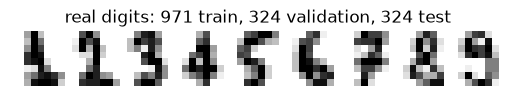

In [1]:
import random, math, heapq, itertools, warnings
from collections import deque
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, confusion_matrix
warnings.filterwarnings("ignore")
SEEDS, N_SEARCH, N_CSP = range(5), 20, 10         # 5 runs; puzzles per run (use smaller numbers for a faster run)

d = load_digits()
X, y = d.data / 16, d.target
X, y = X[y > 0], y[y > 0]                         # Sudoku has no 0
Xtr, Xr, ytr, yr = train_test_split(X, y, train_size=.6, stratify=y, random_state=0)
Xva, Xte, yva, yte = train_test_split(Xr, yr, train_size=.5, stratify=yr, random_state=0)
plt.imshow(np.hstack([Xtr[ytr == k][0].reshape(8, 8) for k in range(1, 10)]), cmap="gray_r"); plt.axis("off")
plt.title(f"real digits: {len(Xtr)} train, {len(Xva)} validation, {len(Xte)} test"); plt.show()

In [2]:
from sklearn.metrics import accuracy_score

# 1. Train and Evaluate Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=0)
lr_model.fit(Xtr, ytr)

lr_train_acc = lr_model.score(Xtr, ytr)
lr_val_acc = lr_model.score(Xva, yva)

print("--- Logistic Regression ---")
print(f"Training Accuracy:   {lr_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {lr_val_acc * 100:.2f}%")
print()

# 2. Train and Evaluate MLP Classifier (Neural Network)
mlp_model = MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, random_state=0)
mlp_model.fit(Xtr, ytr)

mlp_train_acc = mlp_model.score(Xtr, ytr)
mlp_val_acc = mlp_model.score(Xva, yva)

print("--- MLP Classifier (Neural Network) ---")
print(f"Training Accuracy:   {mlp_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {mlp_val_acc * 100:.2f}%")

--- Logistic Regression ---
Training Accuracy:   98.56%
Validation Accuracy: 95.68%

--- MLP Classifier (Neural Network) ---
Training Accuracy:   100.00%
Validation Accuracy: 97.22%


## 2. Neural network
One hidden layer (128 units). **Temperature scaling** (a number *T* chosen on the validation set) makes the probabilities honest; the search cost is built from them.
Baseline: logistic regression.

                                accuracy  log_loss
MLP (raw)                          0.978     0.116
MLP (temperature T=1.30)           0.978     0.099
Logistic regression (baseline)     0.960     0.186


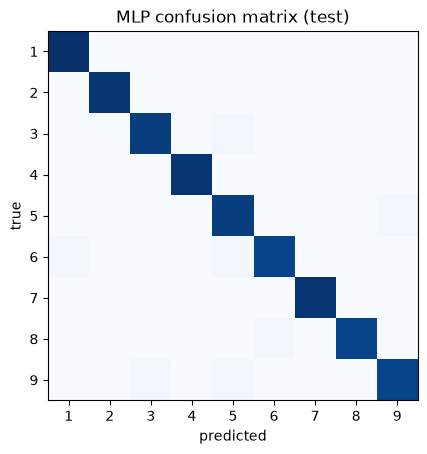

In [3]:
clf = MLPClassifier((128,), alpha=1e-3, batch_size=64, learning_rate_init=2e-3,
                    max_iter=300, tol=1e-5, n_iter_no_change=15, random_state=0).fit(Xtr, ytr)

def proba(X, T=1.0):
    z = np.log(np.clip(clf.predict_proba(np.atleast_2d(X)), 1e-12, 1)) / T
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

T = min(np.linspace(.3, 5, 95), key=lambda t: log_loss(yva, proba(Xva, t), labels=range(1, 10)))
net = lambda X: proba(X, T)                       # calibrated probabilities
read = lambda X: net(X).argmax(1) + 1             # most probable digit
base = LogisticRegression(max_iter=3000).fit(Xtr, ytr)

res = {"MLP (raw)": proba(Xte), "MLP (temperature T=%.2f)" % T: net(Xte), "Logistic regression (baseline)": base.predict_proba(Xte)}
print(pd.DataFrame({n: dict(accuracy=(p.argmax(1) + 1 == yte).mean(), log_loss=log_loss(yte, p, labels=range(1, 10)))
                    for n, p in res.items()}).T.round(3))
plt.imshow(confusion_matrix(yte, read(Xte)), cmap="Blues"); plt.xticks(range(9), range(1, 10)); plt.yticks(range(9), range(1, 10))
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("MLP confusion matrix (test)"); plt.grid(False); plt.show()

## 3. CSP: Backtracking, Forward Checking, AC-3
Variables = 81 cells, domain = digits 1-9, constraint = a cell differs from its 20 *peers* (same row, column, box).
`fc` = remove the chosen digit from the peers' domains. `ac` = AC-3 before the search: a peer with only one possible digit removes it from this cell.
Counters: `assignments`, `backtracks`.

In [4]:
UNITS = ([[r*9 + c for c in range(9)] for r in range(9)] + [[r*9 + c for r in range(9)] for c in range(9)] +
         [[(br*3 + r)*9 + bc*3 + c for r in range(3) for c in range(3)] for br in range(3) for bc in range(3)])
PEERS = [sorted({p for u in UNITS if i in u for p in u} - {i}) for i in range(81)]

def duplicates(g):                                # digits repeated inside a row, column or box
    return [(v, [c for c in u if g[c] == v]) for u in UNITS for v in set(g[c] for c in u) - {0} if [g[c] for c in u].count(v) > 1]

def solve(grid, fc=True, ac=True, mrv=False, n=1):
    """Backtracking on a grid (0 = empty). Returns (solutions, counters, message)."""
    st, g, sols = dict(assignments=0, backtracks=0), list(grid), []
    dom = [{v} if v else set(range(1, 10)) for v in grid]

    def forward_check(dom, i, v):                 # remove v from the empty peers of cell i
        for p in PEERS[i]:
            if g[p] == 0 and v in dom[p]:
                dom[p].discard(v)
                if not dom[p]: return False
        return True

    def ac3():
        queue = deque((a, b) for a in range(81) for b in PEERS[a])
        while queue:
            a, b = queue.popleft()
            if len(dom[b]) == 1 and dom[a] & dom[b]:     # b is forced to one digit, so a cannot use it
                dom[a] = dom[a] - dom[b]
                if not dom[a]: return False
                queue.extend((c, a) for c in PEERS[a] if c != b)
        return True

    if ac and not ac3(): return [], st, "no solution: AC-3 emptied a domain (the givens contradict each other)"
    if duplicates(g): return [], st, "no solution: a digit is repeated in a row, column or box"
    if fc and not all(forward_check(dom, i, g[i]) for i in range(81) if g[i]): return [], st, "no solution: a cell has no legal digit left"

    def rec(dom):
        free = [i for i in range(81) if g[i] == 0]
        if not free:
            sols.append(tuple(g)); return len(sols) >= n
        i = min(free, key=lambda c: len(dom[c])) if mrv else free[0]
        for v in sorted(dom[i]):
            if not fc and any(g[p] == v for p in PEERS[i]): continue
            st["assignments"] += 1; g[i] = v
            if fc:
                new = [set(x) for x in dom]; new[i] = {v}
                if forward_check(new, i, v) and rec(new): return True
            elif rec(dom): return True
            g[i] = 0; st["backtracks"] += 1
        return False

    rec(dom)
    return sols, st, "ok" if sols else "no solution: the search tried everything"

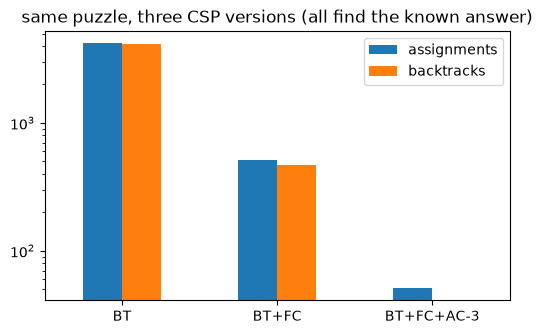

In [5]:
PUZ = [int(c) for c in "530070000600195000098000060800060003400803001700020006060000280000419005000080079"]
SOL = tuple(int(c) for c in "534678912672195348198342567859761423426853791713924856961537284287419635345286179")
VERSIONS = [("BT", 0, 0), ("BT+FC", 1, 0), ("BT+FC+AC-3", 1, 1)]
pd.DataFrame({m: solve(PUZ, fc, ac)[1] for m, fc, ac in VERSIONS}).T.plot.bar(rot=0, logy=True, figsize=(6, 3.5),
              title="same puzzle, three CSP versions (all find the known answer)"); plt.show()

## 4. Search for the cheapest corrections
* **State:** a set of corrections `{(cell, new digit)}` to the first reading. **Action:** change one more of the 10 least confident cells to one of its 2 next-best digits.
* **Cost** = log p(read digit) − log p(new digit): a likely correction is cheap. **Goal:** no repeated digit and the CSP solves it.
* **UCS** orders by cost so far *g*, **Greedy** by (conflicts, *h*), **A\*** by *g + h*.
* **h:** every repeated-digit conflict needs ≥ 1 more change costing ≥ the cheapest option of its cells; we take the **max** over conflicts, so *h* never overestimates.
* Counters: `expanded`, `generated`, `tests` (= CSP calls).

In [6]:
def candidate_moves(probs, rd, n_cells=10, n_alt=2):
    probs, options = np.clip(probs, 1e-12, 1), {}
    for c in sorted([i for i in range(81) if rd[i]], key=lambda i: probs[i][rd[i] - 1])[:n_cells]:
        alts = [int(d) + 1 for d in np.argsort(-probs[c]) if d + 1 != rd[c]][:n_alt]
        options[c] = [(d, math.log(probs[c][rd[c] - 1] / probs[c][d - 1])) for d in alts]
    return options

def estimate(grid, options, used):                # (h, number of conflicts)
    costs = [min([k for c in cells if c not in used for _, k in options.get(c, [])], default=math.inf) for _, cells in duplicates(grid)]
    return max(costs, default=0), len(costs)

def correction_search(rd, options, algo="astar", max_corrections=3, max_tests=1500):
    out = dict(status="unreadable", corrections=[], cost=None, solution=None, expanded=0, generated=1, tests=0, trace=[])
    cost_of = {(c, d): k for c, lst in options.items() for d, k in lst}
    prio = lambda g, h, n: {"ucs": g, "greedy": (n, h), "astar": g + h}[algo]
    tie = itertools.count()
    h, n = estimate(rd, options, set())
    frontier, seen = [(prio(0, h, n), next(tie), 0.0, frozenset())], {frozenset()}
    while frontier and out["tests"] < max_tests:
        _, _, g, state = heapq.heappop(frontier)
        grid = list(rd)
        for c, d in state: grid[c] = d
        out["expanded"] += 1; out["tests"] += 1; out["trace"].append(g)
        sols = [] if duplicates(grid) else solve(grid, mrv=True)[0]          # goal test = the CSP
        if sols:
            out.update(status="solved", cost=g, solution=sols[0], corrections=[(c, rd[c], d, cost_of[(c, d)]) for c, d in sorted(state)])
            break
        used = {c for c, _ in state}
        for c, lst in options.items():
            for d, k in ([] if c in used or len(state) == max_corrections else lst):
                new = state | {(c, d)}
                if new in seen: continue
                seen.add(new)
                ngrid = list(grid); ngrid[c] = d
                h, n = estimate(ngrid, options, used | {c})
                if algo == "astar" and h == math.inf: continue                # a conflict that can no longer be repaired
                out["generated"] += 1
                heapq.heappush(frontier, (prio(g + k, h, n), next(tie), g + k, new))
    return out

def known_example():                              # cell 1 is really a 3, but was read as 5 (probability .50 vs .45)
    rd = list(PUZ); rd[1] = 5
    probs = np.full((81, 9), .03 / 8)
    for i, v in enumerate(rd):
        if v: probs[i][v - 1] = .97
    probs[1] = .0025; probs[1][4], probs[1][2] = .50, .45
    return rd, candidate_moves(probs, rd)

rd0, options0 = known_example()
rows = {a: correction_search(rd0, options0, a) for a in ["ucs", "greedy", "astar"]}
assert all(r["solution"] == SOL and r["corrections"][0][:3] == (1, 5, 3) for r in rows.values())       # known answer
pd.DataFrame(rows).T[["expanded", "generated", "tests", "cost"]]

,expanded,generated,tests,cost
ucs,2,21,2,0.105361
greedy,2,21,2,0.105361
astar,2,18,2,0.105361


## 5. Generated data: puzzles and handwritten 9x9 pictures

In [7]:
def make_puzzles(rng, givens_list):               # puzzles with a unique solution and the requested numbers of givens
    targets = sorted(givens_list, reverse=True)
    while True:
        g = [0] * 81
        for b in range(3):                        # fill the 3 diagonal boxes randomly, the CSP finishes the grid
            for k, v in enumerate(rng.sample(range(1, 10), 9)): g[(b*3 + k//3)*9 + b*3 + k%3] = v
        sol = list(solve(g, mrv=True)[0][0])
        puz, snaps, n = list(sol), {}, 81
        for cell in rng.sample(range(81), 81):
            if n <= targets[-1]: break
            old, puz[cell] = puz[cell], 0
            if len(solve(puz, mrv=True, n=2)[0]) == 1:                   # still exactly one solution: keep the removal
                n -= 1
                if n in targets: snaps[n] = list(puz)
            else: puz[cell] = old
        if len(snaps) == len(targets): return sol, snaps

clean = {k: np.where((yte == k) & (read(Xte) == k))[0] for k in range(1, 10)}      # test images read correctly
anyimg = {k: np.where(yte == k)[0] for k in range(1, 10)}

def hard_digit(d, rng):                           # a blend the network reads as another digit, but unsure
    while True:
        xd = Xte[rng.choice(anyimg[d])]
        c = rng.choice([k for k in range(1, 10) if k != d])
        xc = Xte[rng.choice(anyimg[c])]
        a = rng.choice([.35 + .05*i for i in range(9)])
        x = (1 - a) * xd + a * xc
        p = net(x)[0]; top = np.argsort(-p)
        if top[0] + 1 == c and top[1] + 1 == d and p[c - 1] <= .90 and p[d - 1] >= .05: return x

def make_instance(puzzle, k, rng):                # 81 cell images; k of the given cells are hard digits
    noise = np.random.default_rng(rng.randrange(10**9))
    cells = np.clip(noise.normal(0, .01, (81, 64)), 0, .1)                 # blank = dark noise
    bad = rng.sample([i for i in range(81) if puzzle[i]], k)
    for i in range(81):
        if puzzle[i]: cells[i] = hard_digit(puzzle[i], rng) if i in bad else Xte[rng.choice(clean[puzzle[i]])]
    return cells, bad

mosaic = lambda cells: np.vstack([np.hstack([cells[r*9 + c].reshape(8, 8) for c in range(9)]) for r in range(9)])

## 6. Integration: NN → AC-3 → Search → CSP
`mode="nn"`: costs from the network. `"none"`: no correction. `"random"`: random candidates and costs (control experiment).

In [8]:
def solve_image(cells, mode="nn", algo="astar", max_corrections=3, max_tests=1500, rng=None):
    blank = cells.max(1) < .25
    probs = np.zeros((81, 9)); probs[~blank] = net(cells[~blank])
    rd = [0 if blank[i] else int(probs[i].argmax()) + 1 for i in range(81)]
    least = sorted([i for i in range(81) if rd[i]], key=lambda i: probs[i][rd[i] - 1])[:5]
    out = dict(read=rd, probs=probs, status="unreadable", solution=None, search=None,
               message="unreadable: no solvable puzzle found. Least confident cells (row, col, digit, probability): "
                       + str([(i//9 + 1, i%9 + 1, rd[i], round(float(probs[i][rd[i] - 1]), 2)) for i in least]))
    sols = solve(rd, mrv=True)[0]                 # first try the reading as it is
    if sols: out.update(status="solved", solution=sols[0], message="the first reading is already solvable")
    elif mode != "none":
        rng = rng or random.Random(0)
        options = candidate_moves(probs, rd) if mode == "nn" else {c: [(d, rng.random()) for d in rng.sample(
            [x for x in range(1, 10) if x != rd[c]], 2)] for c in range(81) if rd[c]}
        s = out["search"] = correction_search(rd, options, algo if mode == "nn" else "ucs", max_corrections, max_tests)
        if s["status"] == "solved": out.update(status="solved", solution=s["solution"], corrections=s["corrections"], message="solved with corrections")
    return out

## 7. Demo
One puzzle with 2 hard digits (`DEMO_MISREADS = 3` is harder). The figure shows: **1** input, **2** NN reading, **3** corrected puzzle, **4** search trace (UCS / Greedy / A*),
**5** CSP pruning without and with FC / AC-3, **6** solution with the NN **on** versus **off**.

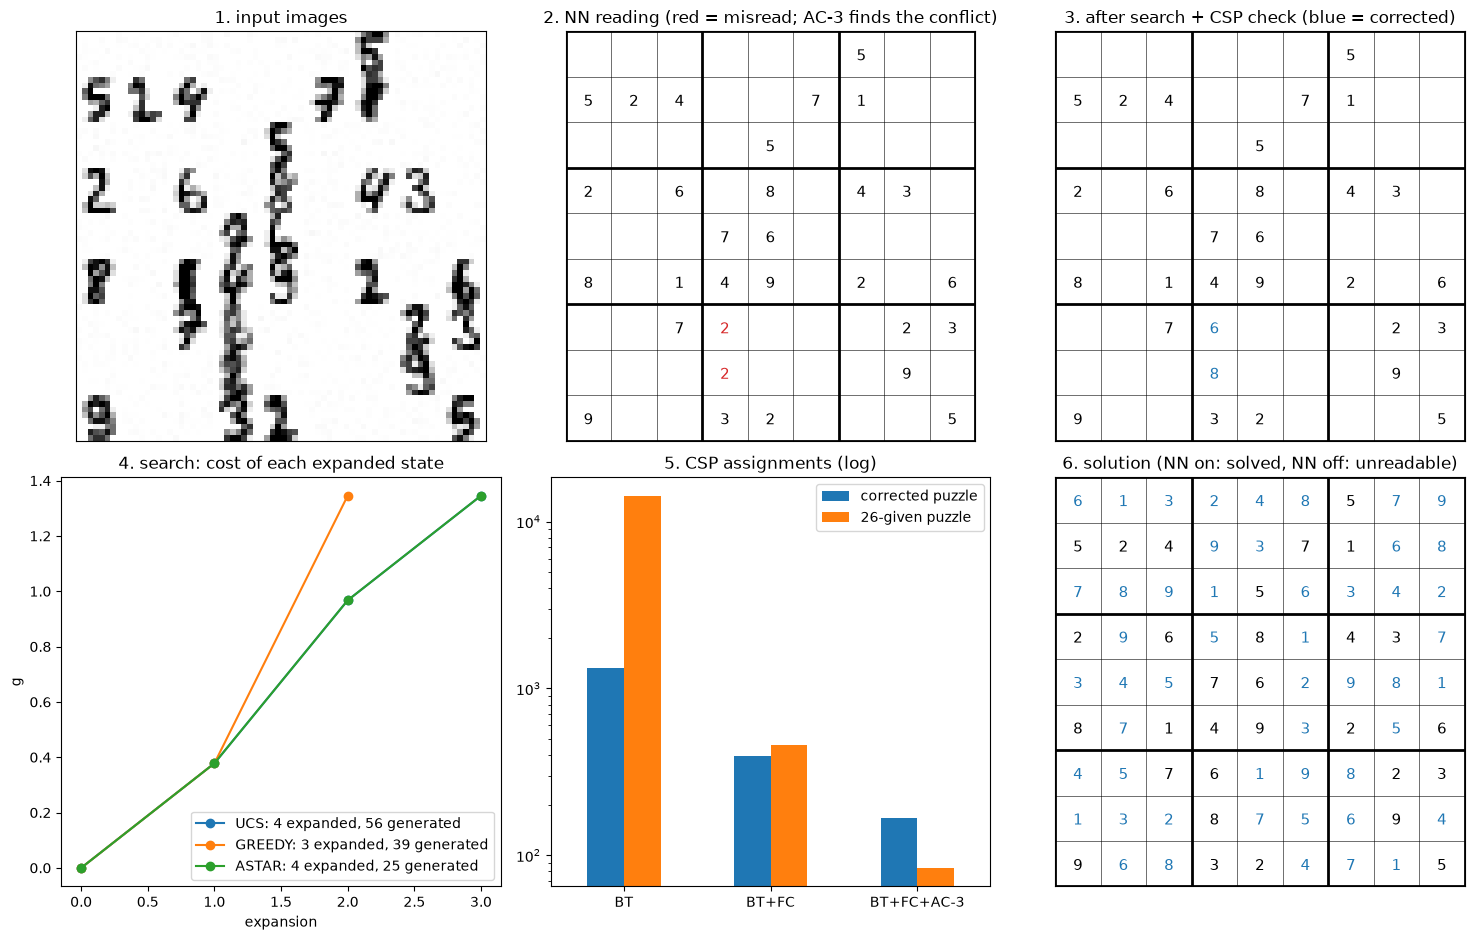

corrections (cell, read, new, cost): [(57, 2, 6, 0.38), (66, 2, 8, 0.97)]  true digits: [6, 8]
impossible case: unreadable: no solvable puzzle found. Least confident cells (row, col, digit, probability): [(1, 3, 5, 0.9), (8, 5, 1, 0.96), (2, 5, 9, 0.98), (5, 9,  ...


In [9]:
DEMO_SEED, DEMO_MISREADS = 7, 2
for attempt in range(200):                        # find an instance where the first reading is wrong but A* repairs it
    rng = random.Random(DEMO_SEED * 1000 + attempt)
    sol, snaps = make_puzzles(rng, [30])
    cells, bad = make_instance(snaps[30], DEMO_MISREADS, rng)
    on, off = solve_image(cells), solve_image(cells, "none")
    if on["status"] == "solved" and tuple(on["solution"]) == tuple(sol) and off["status"] != "solved": break

rd = on["read"]
runs = {a: correction_search(rd, candidate_moves(on["probs"], rd), a) for a in ["ucs", "greedy", "astar"]}
fixed = list(rd)
for c, _, new, _ in on["corrections"]: fixed[c] = new
hard = make_puzzles(random.Random(DEMO_SEED), [26])[1][26]
steps = pd.DataFrame({n: {m: solve(g, fc, ac)[1]["assignments"] for m, fc, ac in VERSIONS} for n, g in [("corrected puzzle", fixed), ("26-given puzzle", hard)]})

def draw(ax, g, title, red=(), blue=()):
    ax.set(xlim=(0, 9), ylim=(9, 0), xticks=[], yticks=[], title=title, aspect="equal"); ax.grid(False)
    for k in range(10): ax.axhline(k, color="k", lw=2 if k % 3 == 0 else .4); ax.axvline(k, color="k", lw=2 if k % 3 == 0 else .4)
    for i, v in enumerate(g):
        if v: ax.text(i%9 + .5, i//9 + .55, v, ha="center", va="center", fontsize=11, color="#d62728" if i in red else "#1f77b4" if i in blue else "k")

fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))
ax[0, 0].imshow(mosaic(cells), cmap="gray_r", interpolation="nearest"); ax[0, 0].set(title="1. input images", xticks=[], yticks=[]); ax[0, 0].grid(False)
draw(ax[0, 1], rd, "2. NN reading (red = misread; AC-3 finds the conflict)" if "AC-3" in solve(rd)[2] else "2. NN reading (red = misread)", red=bad)
draw(ax[0, 2], fixed, "3. after search + CSP check (blue = corrected)", blue={c[0] for c in on["corrections"]})
for a, r in runs.items(): ax[1, 0].plot(r["trace"], "o-", label=f"{a.upper()}: {r['expanded']} expanded, {r['generated']} generated")
ax[1, 0].set(title="4. search: cost of each expanded state", xlabel="expansion", ylabel="g"); ax[1, 0].legend()
steps.plot.bar(ax=ax[1, 1], logy=True, rot=0, title="5. CSP assignments (log)")
draw(ax[1, 2], list(on["solution"]), f"6. solution (NN on: {on['status']}, NN off: {off['status']})", blue={i for i in range(81) if not fixed[i]})
plt.tight_layout(); plt.show()
print("corrections (cell, read, new, cost):", [(c, a, b, round(k, 2)) for c, a, b, k in on["corrections"]], " true digits:", [sol[c[0]] for c in on["corrections"]])
print("impossible case:", solve_image(make_instance(PUZ[:2] + [5] + PUZ[3:], 0, random.Random(5))[0], max_corrections=0)["message"][:150], "...")

## 8. Experiments (5 seeds, mean ± std over the seeds)
1. **UCS vs Greedy vs A\*** for 0-4 misread digits. 2. **BT vs BT+FC vs BT+FC+AC-3** for 35 / 30 / 25 givens. 3. **NN-guided vs no correction vs random correction** (same budget: 300 CSP tests).
`exact` = the returned solution is the true one; `solved` = a solvable puzzle was returned (maybe the wrong one).

In [10]:
rows = []
for seed in SEEDS:
    rng = random.Random(seed)
    puzzles = [make_puzzles(rng, [30]) for _ in range(N_SEARCH)]
    for k in range(5):
        for pi, (sol, snaps) in enumerate(puzzles):
            cells, _ = make_instance(snaps[30], k, random.Random(seed*1000 + k*50 + pi))
            for method, mode, algo, budget in [("UCS", "nn", "ucs", 1500), ("Greedy", "nn", "greedy", 1500), ("A*", "nn", "astar", 1500),
                                               ("A* (NN)", "nn", "astar", 300), ("No correction", "none", "astar", 300), ("Random correction", "random", "ucs", 300)]:
                r = solve_image(cells, mode, algo, max_tests=budget, rng=random.Random(pi))
                s, ok = r["search"] or dict(expanded=0, generated=0, tests=0, cost=0.0), r["status"] == "solved"
                rows.append(dict(seed=seed, misreads=k, method=method, budget=budget, solved=float(ok), exact=float(ok and tuple(r["solution"]) == tuple(sol)),
                                 expanded=s["expanded"], generated=s["generated"], tests=s["tests"], cost=s["cost"] if ok else np.nan))
search_df = pd.DataFrame(rows)

rows = []
for seed in SEEDS:
    rng = random.Random(100 + seed)
    for _ in range(N_CSP):
        for givens, puz in make_puzzles(rng, [35, 30, 25])[1].items():
            for m, fc, ac in VERSIONS:
                st = solve(puz, fc, ac)[1]
                rows.append(dict(seed=seed, givens=givens, method=m, assignments=st["assignments"], backtracks=st["backtracks"]))
csp_df = pd.DataFrame(rows)

def agg(df, keys):                                # mean of each seed, then mean and std over the 5 seeds
    g = df.groupby(keys + ["seed"]).mean(numeric_only=True).groupby(keys)
    return g.mean(), g.std(ddof=0)

def show(df, keys, cols, titles, kind="line", logy=()):          # one plot per column (mean with std bars) + the table
    m, s = agg(df, keys)
    fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.8))
    for a, c, t in zip(np.atleast_1d(ax), cols, titles):
        m[c].unstack().plot(ax=a, kind=kind, yerr=s[c].unstack(), capsize=3, title=t, logy="sym" if c in logy else False, **({"marker": "o"} if kind == "line" else {"rot": 0}))
        a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3)
    plt.tight_layout(); plt.show()
    return m[cols].round(2).astype(str) + " ± " + s[cols].round(2).astype(str)

### Experiment 1: UCS vs Greedy vs A*

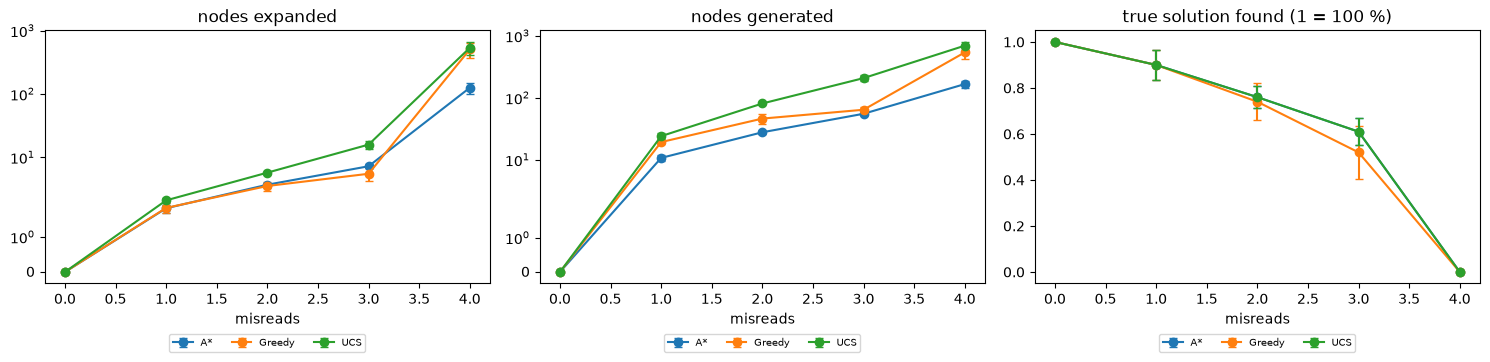

expanded        generated        exact
misreads method                                               
0        A*            0.0 ± 0.0        0.0 ± 0.0    1.0 ± 0.0
         Greedy        0.0 ± 0.0        0.0 ± 0.0    1.0 ± 0.0
         UCS           0.0 ± 0.0        0.0 ± 0.0    1.0 ± 0.0
1        A*          1.81 ± 0.14      10.7 ± 1.03   0.9 ± 0.06
         Greedy      1.82 ± 0.14     19.26 ± 1.53   0.9 ± 0.06
         UCS          2.09 ± 0.2     24.01 ± 2.58   0.9 ± 0.06
2        A*          3.69 ± 0.09     27.72 ± 1.85  0.76 ± 0.05
         Greedy       3.52 ± 0.6     46.07 ± 8.15  0.74 ± 0.08
         UCS         5.72 ± 0.21     80.73 ± 2.93  0.76 ± 0.05
3        A*          7.21 ± 0.48       55.1 ± 3.3  0.61 ± 0.06
         Greedy       5.49 ± 1.3     63.97 ± 6.38  0.52 ± 0.12
         UCS        15.83 ± 2.17   207.07 ± 24.13  0.61 ± 0.06
4        A*       124.77 ± 25.85    165.78 ± 20.5    0.0 ± 0.0
         Greedy  502.61 ± 129.36  537.62 ± 120.19    0.0 ± 0.0
         UCS      532.0 ± 127.66  690.85 ± 101.91    0.0 ± 0.0

In [11]:
e1 = search_df[search_df.budget == 1500]
show(e1, ["misreads", "method"], ["expanded", "generated", "exact"], ["nodes expanded", "nodes generated", "true solution found (1 = 100 %)"], logy=("expanded", "generated"))

### Experiment 2: BT vs BT+FC vs BT+FC+AC-3

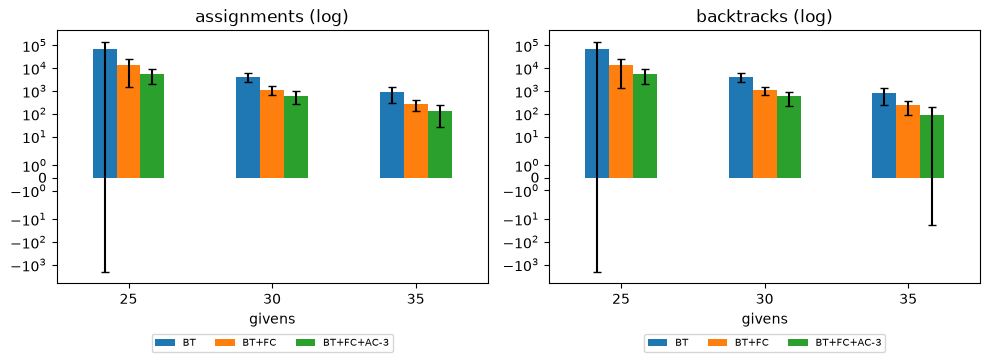

assignments           backtracks
givens method                                              
25     BT          69883.36 ± 71943.82  69827.36 ± 71943.82
       BT+FC        13899.1 ± 12460.04   13843.1 ± 12460.04
       BT+FC+AC-3    5842.88 ± 3842.68    5786.88 ± 3842.68
30     BT             4320.1 ± 1759.92     4269.1 ± 1759.92
       BT+FC          1155.08 ± 454.74     1104.08 ± 454.74
       BT+FC+AC-3      628.84 ± 347.99      577.84 ± 347.99
35     BT               862.5 ± 565.96       816.5 ± 565.96
       BT+FC           277.84 ± 142.72      231.84 ± 142.72
       BT+FC+AC-3       134.0 ± 106.35        88.0 ± 106.35

In [12]:
show(csp_df, ["givens", "method"], ["assignments", "backtracks"], ["assignments (log)", "backtracks (log)"], kind="bar", logy=("assignments", "backtracks"))

### Experiment 3: NN-guided vs no correction vs random correction

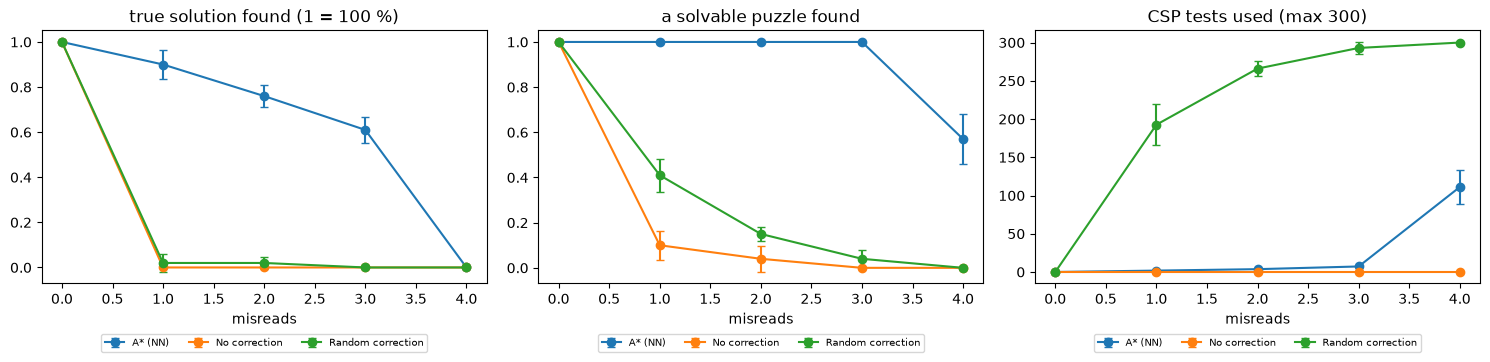

exact       solved           tests
misreads method                                                     
0        A* (NN)              1.0 ± 0.0    1.0 ± 0.0       0.0 ± 0.0
         No correction        1.0 ± 0.0    1.0 ± 0.0       0.0 ± 0.0
         Random correction    1.0 ± 0.0    1.0 ± 0.0       0.0 ± 0.0
1        A* (NN)             0.9 ± 0.06    1.0 ± 0.0     1.81 ± 0.14
         No correction        0.0 ± 0.0   0.1 ± 0.06       0.0 ± 0.0
         Random correction  0.02 ± 0.04  0.41 ± 0.07  192.59 ± 26.44
2        A* (NN)            0.76 ± 0.05    1.0 ± 0.0     3.69 ± 0.09
         No correction        0.0 ± 0.0  0.04 ± 0.06       0.0 ± 0.0
         Random correction  0.02 ± 0.02  0.15 ± 0.03   265.94 ± 9.81
3        A* (NN)            0.61 ± 0.06    1.0 ± 0.0     7.21 ± 0.48
         No correction        0.0 ± 0.0    0.0 ± 0.0       0.0 ± 0.0
         Random correction    0.0 ± 0.0  0.04 ± 0.04   292.95 ± 7.83
4        A* (NN)              0.0 ± 0.0  0.57 ± 0.11  111.07 ± 21.98
         No correction        0.0 ± 0.0    0.0 ± 0.0       0.0 ± 0.0
         Random correction    0.0 ± 0.0    0.0 ± 0.0     300.0 ± 0.0

In [13]:
e3 = search_df[search_df.budget == 300]
show(e3, ["misreads", "method"], ["exact", "solved", "tests"], ["true solution found (1 = 100 %)", "a solvable puzzle found", "CSP tests used (max 300)"])

## 9. Tests: 5 normal, 3 edge, 2 impossible

In [14]:
def normal_1_csp_known_answer(): assert solve(PUZ)[0][0] == SOL
def normal_2_pruning_helps(): a = [solve(PUZ, fc, ac)[1]["assignments"] for _, fc, ac in VERSIONS]; assert a[0] > a[1] > a[2]
def normal_3_search_known_answer(): assert all(correction_search(*known_example(), a)["solution"] == SOL for a in ["ucs", "greedy", "astar"])
def normal_4_nn_beats_baseline(): assert (read(Xte) == yte).mean() > .9 and (read(Xte) == yte).mean() >= base.score(Xte, yte) - .02
def normal_5_pipeline_fixes_one_misread():
    ok = 0
    for s in range(6):
        rng = random.Random(s); sol_, sn = make_puzzles(rng, [32]); r = solve_image(make_instance(sn[32], 1, rng)[0])
        assert r["status"] == "solved"; ok += tuple(r["solution"]) == tuple(sol_)
    assert ok >= 4
def edge_1_complete_grid(): assert solve(list(SOL))[0][0] == SOL and solve(list(SOL))[1]["assignments"] == 0
def edge_2_empty_grid(): assert len(solve([0] * 81, mrv=True, n=2)[0]) == 2
def edge_3_zero_corrections_allowed(): assert correction_search(*known_example(), max_corrections=0)["status"] == "unreadable"
def impossible_1_repeated_digit():
    for fc, ac in [(1, 1), (0, 0)]: assert solve(PUZ[:2] + [5] + PUZ[3:], fc, ac)[2].startswith("no solution")
def impossible_2_unreadable_message():
    assert solve_image(make_instance(PUZ[:2] + [5] + PUZ[3:], 0, random.Random(5))[0], max_corrections=0)["message"].startswith("unreadable")

names = [n for n in list(globals()) if n.split("_")[0] in ("normal", "edge", "impossible") and callable(globals()[n])]
for n in names: globals()[n]()
print(len(names), "tests passed:", ", ".join(names))

10 tests passed: normal_1_csp_known_answer, normal_2_pruning_helps, normal_3_search_known_answer, normal_4_nn_beats_baseline, normal_5_pipeline_fixes_one_misread, edge_1_complete_grid, edge_2_empty_grid, edge_3_zero_corrections_allowed, impossible_1_repeated_digit, impossible_2_unreadable_message


## 10. Limits and conclusions
* **Solvable is not correct:** a cheaper *wrong* correction can also give a solvable puzzle (3 misreads: true solution about 6 times in 10). With 4 misreads (limit: 3 corrections) it is never found, yet about half are "solved" (wrongly).
* **Confident errors are invisible:** only the 10 least confident cells are candidates.
* **Data:** digits are real; puzzles and the 9x9 pictures are generated by the rules in section 1 (not photos of Sudoku sheets); 8x8 digits instead of MNIST.
* **Conclusion:** calibrated probabilities turn "the puzzle is broken" into a ranked list of repairs; A* finds the cheapest with fewer nodes than UCS; FC and AC-3 make each CSP check cheaper; without the network's probabilities correction is hopeless (experiment 3).

**Discussion cheat sheet:** why not take the top digit? (one wrong digit breaks the puzzle) · why temperature scaling? (costs are log-probabilities) · why is *h* admissible? (max, not sum, over conflicts) ·
why same cost for UCS and A*? (both optimal) · FC vs AC-3? (FC after every assignment; AC-3 once before the search) · is the data real? (digits yes, the rest by rule).